In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
print(os.listdir('/content/drive/MyDrive/dataset'))

['Technology 10', 'Healthcare 7', 'retail 6', 'Finance 5', 'consumer']


In [ ]:
import os

folder_path = '/content/drive/MyDrive/dataset'

for root, dirs, files in os.walk(folder_path):
    level = root.replace(folder_path, '').count(os.sep)
    indent = ' ' * 4 * level
    print(f'{indent}{os.path.basename(root)}/')

    subindent = ' ' * 4 * (level + 1)
    for file in files:
        print(f'{subindent}{file}')

dataset/
    Technology 10/
        Alphabet/
            Alphabet 2025-q1-earnings-transcript.pdf
            Alphabet 2025-q2-earnings-transcript.pdf
            Alphabet 2025_Q3_Earnings_Transcript.pdf
            Alphabet 2025_Q4_Earnings_Transcript.pdf
            Alphabet 2024-q1-earnings-transcript.pdf
            Alphabet 2024-q2-earnings-transcript.pdf
            Alphabet 2024-q3-earnings-transcript.pdf
            Alphabet 2024-q4-earnings-transcript.pdf
        AMD/
            AMD_1Q_2026_Earnings.pdf
            AMD Fiscal Fourth Quarter and Full Year 2025 Financial Results.pdf
            amd3q2025call.pdf
            amd2q2025.pdf
            AMD Q1 2025 Earnings Call.pdf
            2025-02-04 AMD 4Q Earnings call.pdf
            AMD 3Q24call.pdf
            AMD 2Q24call.pdf
        salesforce/
            Salesforce-Q1-FY27-Earnings-Transcript.pdf
            Transcript-Salesforce-Inc-Q4-FY26-Earnings-Conference-Call-2-25-26.pdf
            Transcript-Salesforce-Inc-Q

In [ ]:
import os

folder_path = "/content/drive/MyDrive/dataset"

pdf_files = []

for root, dirs, files in os.walk(folder_path):
    for file in files:
        if file.lower().endswith(".pdf"):
            pdf_files.append(os.path.join(root, file))

# Print all PDFs
for pdf in pdf_files:
    print(pdf)

print("\nTotal PDFs:", len(pdf_files))

/content/drive/MyDrive/dataset/Technology 10/Alphabet/Alphabet 2025-q1-earnings-transcript.pdf
/content/drive/MyDrive/dataset/Technology 10/Alphabet/Alphabet 2025-q2-earnings-transcript.pdf
/content/drive/MyDrive/dataset/Technology 10/Alphabet/Alphabet 2025_Q3_Earnings_Transcript.pdf
/content/drive/MyDrive/dataset/Technology 10/Alphabet/Alphabet 2025_Q4_Earnings_Transcript.pdf
/content/drive/MyDrive/dataset/Technology 10/Alphabet/Alphabet 2024-q1-earnings-transcript.pdf
/content/drive/MyDrive/dataset/Technology 10/Alphabet/Alphabet 2024-q2-earnings-transcript.pdf
/content/drive/MyDrive/dataset/Technology 10/Alphabet/Alphabet 2024-q3-earnings-transcript.pdf
/content/drive/MyDrive/dataset/Technology 10/Alphabet/Alphabet 2024-q4-earnings-transcript.pdf
/content/drive/MyDrive/dataset/Technology 10/AMD/AMD_1Q_2026_Earnings.pdf
/content/drive/MyDrive/dataset/Technology 10/AMD/AMD Fiscal Fourth Quarter and Full Year 2025 Financial Results.pdf
/content/drive/MyDrive/dataset/Technology 10/AMD/a

In [ ]:
for pdf in pdf_files:
    print(os.path.basename(pdf))

Alphabet 2025-q1-earnings-transcript.pdf
Alphabet 2025-q2-earnings-transcript.pdf
Alphabet 2025_Q3_Earnings_Transcript.pdf
Alphabet 2025_Q4_Earnings_Transcript.pdf
Alphabet 2024-q1-earnings-transcript.pdf
Alphabet 2024-q2-earnings-transcript.pdf
Alphabet 2024-q3-earnings-transcript.pdf
Alphabet 2024-q4-earnings-transcript.pdf
AMD_1Q_2026_Earnings.pdf
AMD Fiscal Fourth Quarter and Full Year 2025 Financial Results.pdf
amd3q2025call.pdf
amd2q2025.pdf
AMD Q1 2025 Earnings Call.pdf
2025-02-04 AMD 4Q Earnings call.pdf
AMD 3Q24call.pdf
AMD 2Q24call.pdf
Salesforce-Q1-FY27-Earnings-Transcript.pdf
Transcript-Salesforce-Inc-Q4-FY26-Earnings-Conference-Call-2-25-26.pdf
Transcript-Salesforce-Inc-Q3-FY26-Earnings-Conference-Call-12-3-25.pdf
Salesforce-Inc-Q2-FY26-Earnings-Conference-Call-9-3-25.pdf
Salesforce-Inc-Q1-2026-Earnings-Call-May-28-2025-1.pdf
Salesforce_Inc_Q4_2025_Earnings_Call_Feb_26_2025_1.pdf
Salesforce-Inc-Q3-FY25-Earnings-Conference-Call-combined.pdf
Salesforce-Inc-Q2-2025-Earnings-C

In [ ]:
!pip install pymupdf

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.7/25.7 MB 84.9 MB/s eta 0:00:00


In [ ]:
import fitz
import os
import pandas as pd

def extract_text_from_pdf(pdf_path):
    text = ""

    try:
        doc = fitz.open(pdf_path)

        for page in doc:
            text += page.get_text()

        doc.close()

    except Exception as e:
        print(f"Error in {pdf_path}: {e}")

    return text

In [ ]:
all_transcripts = []

for pdf in pdf_files:

    text = extract_text_from_pdf(pdf)

    all_transcripts.append({
        "file_path": pdf,
        "file_name": os.path.basename(pdf),
        "raw_text": text
    })

df = pd.DataFrame(all_transcripts)

print("Total transcripts:", len(df))
df.head()

Total transcripts: 228


,file_path,file_name,raw_text
0,/content/drive/MyDrive/dataset/Technology 10/A...,Alphabet 2025-q1-earnings-transcript.pdf,\nThis transcript is provided for the conveni...
1,/content/drive/MyDrive/dataset/Technology 10/A...,Alphabet 2025-q2-earnings-transcript.pdf,\nThis transcript is provided for the conveni...
2,/content/drive/MyDrive/dataset/Technology 10/A...,Alphabet 2025_Q3_Earnings_Transcript.pdf,\nThis transcript is provided for the conveni...
3,/content/drive/MyDrive/dataset/Technology 10/A...,Alphabet 2025_Q4_Earnings_Transcript.pdf,This transcript is provided for the convenienc...
4,/content/drive/MyDrive/dataset/Technology 10/A...,Alphabet 2024-q1-earnings-transcript.pdf,This transcript is provided for the convenienc...


In [ ]:
df.to_csv("raw_transcripts.csv", index=False)

In [ ]:
print(df.iloc[0]["raw_text"][:50000])

 
This transcript is provided for the convenience of investors only, for a full recording please see 
the Q1 2025 Earnings Call webcast.  
 
Operator: Welcome, everyone. Thank you for standing by for the Alphabet First Quarter 2025 
Earnings conference call.  
 
At this time, all participants are in a listen-only mode. After the speaker presentations, there will 
be a question-and-answer session. To ask a question during the session, you will need to press 
*1 on your telephone. 
 
I would now like to hand the conference over to your speaker today, Jim Friedland, Senior 
Director of Investor Relations. Please go ahead.  
 
Jim Friedland, Senior Director, Investor Relations: Thank you. Good afternoon, everyone, 
and welcome to Alphabet's First Quarter 2025 Earnings Conference Call. With us today are 
Sundar Pichai, Philipp Schindler and Anat Ashkenazi. 
 
Now, I'll quickly cover the Safe Harbor. 
 
Some of the statements that we make today regarding our business, operations, and financi

In [ ]:
import re
speaker_pattern = r'([A-Z][A-Za-z\s\.\-]+(?:\([^)]+\))?,.*?):'

In [ ]:
def split_by_speaker(text):

    matches = list(re.finditer(speaker_pattern, text))

    chunks = []

    for i in range(len(matches)):

        start = matches[i].start()

        if i < len(matches)-1:
            end = matches[i+1].start()
        else:
            end = len(text)

        block = text[start:end].strip()

        speaker_line = matches[i].group(1)

        chunks.append({
            "speaker_info": speaker_line,
            "text": block
        })

    return chunks

In [ ]:
speaker_chunks = split_by_speaker(df.iloc[0]["raw_text"])

speaker_chunks[:3]

[{'speaker_info': 'Senior \nDirector of Investor Relations. Please go ahead.  \n \nJim Friedland, Senior Director, Investor Relations',
  'text': "Senior \nDirector of Investor Relations. Please go ahead.  \n \nJim Friedland, Senior Director, Investor Relations: Thank you. Good afternoon, everyone, \nand welcome to Alphabet's First Quarter 2025 Earnings Conference Call. With us today are \nSundar Pichai, Philipp Schindler and Anat Ashkenazi. \n \nNow, I'll quickly cover the Safe Harbor. \n \nSome of the statements that we make today regarding our business, operations, and financial \nperformance may be considered forward-looking. Such statements are based on current \nexpectations and assumptions that are subject to a number of risks and uncertainties.  \n \nActual results could differ materially. Please refer to our Forms 10-K and 10-Q, including the risk \nfactors. We undertake no obligation to update any forward-looking statement. \n \nDuring this call, we will present both GAAP and

In [ ]:
def classify_role(speaker):

    s = speaker.lower()

    if "ceo" in s:
        return "CEO"

    elif "cfo" in s:
        return "CFO"

    elif "investor relations" in s:
        return "IR"

    elif "operator" in s:
        return "Operator"

    elif "(" in s:
        return "Analyst"

    else:
        return "Management"

In [ ]:
all_chunks = []

for idx, row in df.iterrows():

    transcript_chunks = split_by_speaker(row["raw_text"])

    for c in transcript_chunks:

        all_chunks.append({

            "file_name": row["file_name"],

            "speaker": c["speaker_info"],

            "role": classify_role(c["speaker_info"]),

            "text": c["text"]
        })

In [ ]:
import pandas as pd

chunk_df = pd.DataFrame(all_chunks)
chunk_df.head()

,file_name,speaker,role,text
0,Alphabet 2025-q1-earnings-transcript.pdf,Senior \nDirector of Investor Relations. Pleas...,IR,Senior \nDirector of Investor Relations. Pleas...
1,Alphabet 2025-q1-earnings-transcript.pdf,"Sundar. \n \nSundar Pichai, CEO, Alphabet and...",CEO,"Sundar. \n \nSundar Pichai, CEO, Alphabet and..."
2,Alphabet 2025-q1-earnings-transcript.pdf,"Next, YouTube. Yesterday marked a historic mil...",Management,"Next, YouTube. Yesterday marked a historic mil..."
3,Alphabet 2025-q1-earnings-transcript.pdf,"Philipp Schindler, SVP and CBO, Google",Management,"Philipp Schindler, SVP and CBO, Google: Thanks..."
4,Alphabet 2025-q1-earnings-transcript.pdf,"Anat Ashkenazi, SVP and CFO, Alphabet and Google",CFO,"Anat Ashkenazi, SVP and CFO, Alphabet and Goog..."


In [ ]:
# Filter your chunk_df to exclude non-informative dialogue turns
clean_chunk_df = chunk_df[chunk_df['role'] != 'Operator'].copy()

In [ ]:
import re

def clean_raw_text(text):
    if not isinstance(text, str):
        return ""

    # 1. Remove running headers/footers or page counters (e.g., "Page 5 of 20", "Alphabet Inc. Q1")
    text = re.sub(r'(Page\s+\d+\s+of\s+\d+|[A-Za-z\s\.\-]+Q\d\s+\d{4})', '', text, flags=re.IGNORECASE)

    # 2. Remove boilerplate URLs or database stamp references
    text = re.sub(r'(www\.[a-z0-9\.\-]+|[a-z0-9\.\-]+@[a-z0-9\.\-]+)', '', text, flags=re.IGNORECASE)

    # 3. Clean up formatting breaks: Replace newline artifacts (\n) or tabs with spaces
    text = text.replace('\n', ' ').replace('\t', ' ')

    # 4. Handle hyphenation splits caused by page column margins (e.g., "de- \n velopment")
    text = re.sub(r'(\w+)-\s+(\w+)', r'\1\2', text)

    # 5. Collapse multi-spaces down to single spaces
    text = re.sub(r'\s+', ' ', text)

    return text.strip()

# Apply this to the raw text inside your chunk dataframe before sentence splitting
clean_chunk_df['text'] = clean_chunk_df['text'].apply(clean_raw_text)

In [ ]:
def extract_qa_section(raw_text):
    # Common headers that denote the start of the Q&A segment
    qa_markers = [
        "questions and answers",
        "question-and-answer session",
        "q&a session",
        "turn the call over to questions"
    ]

    lower_text = raw_text.lower()

    for marker in qa_markers:
        if marker in lower_text:
            # Find the starting character index of the marker
            start_idx = lower_text.find(marker)
            # Return everything from the marker to the end of the document
            return raw_text[start_idx:]

    # If no structural Q&A marker is found, fall back to returning the whole text
    return raw_text

In [ ]:
!pip install nltk
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [ ]:
import nltk
nltk.download('punkt_tab')

from nltk.tokenize import sent_tokenize

sentence_data = []

# Iterate over clean_chunk_df which holds the cleaned text and speaker info
for _, row in clean_chunk_df.iterrows():

    # Tokenize the text into sentences
    sentences = sent_tokenize(row["text"])

    for sent in sentences:
        clean_sent = sent.strip()

        # Filter: Only keep sentences that have a realistic length (e.g., more than 5 words)
        if len(clean_sent.split()) > 5:
            sentence_data.append({
                "file_name": row["file_name"],
                "speaker": row["speaker"],
                "role": row["role"],
                "sentence": clean_sent
            })


[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


In [ ]:
import pandas as pd

sentence_df = pd.DataFrame(sentence_data)

sentence_df.head()

,file_name,speaker,role,sentence
0,Alphabet 2025-q1-earnings-transcript.pdf,Senior \nDirector of Investor Relations. Pleas...,IR,"Jim Friedland, Senior Director, Investor Relat..."
1,Alphabet 2025-q1-earnings-transcript.pdf,Senior \nDirector of Investor Relations. Pleas...,IR,"Good afternoon, everyone, and welcome to Alpha..."
2,Alphabet 2025-q1-earnings-transcript.pdf,Senior \nDirector of Investor Relations. Pleas...,IR,"With us today are Sundar Pichai, Philipp Schin..."
3,Alphabet 2025-q1-earnings-transcript.pdf,Senior \nDirector of Investor Relations. Pleas...,IR,"Now, I'll quickly cover the Safe Harbor."
4,Alphabet 2025-q1-earnings-transcript.pdf,Senior \nDirector of Investor Relations. Pleas...,IR,Some of the statements that we make today rega...


In [ ]:
def classify_statement(sentence):

    s = sentence.lower()

    # Forward-looking
    if any(word in s for word in [
        "expect", "forecast", "anticipate",
        "outlook", "looking ahead", "guidance"
    ]):
        return "Forward Looking"

    # Risk / uncertainty
    elif any(word in s for word in [
        "risk", "uncertain", "pressure",
        "challenge", "headwind", "may", "could"
    ]):
        return "Risk"

    # AI strategy
    elif any(word in s for word in [
        "ai", "gemini", "llm",
        "agent", "model"
    ]):
        return "AI Strategy"

    # Financial performance
    elif any(word in s for word in [
        "revenue", "growth", "margin",
        "profit", "income", "cash flow"
    ]):
        return "Financial Performance"

    else:
        return "Operational"

In [ ]:
sentence_df["category"] = (
    sentence_df["sentence"]
    .apply(classify_statement)
)

In [ ]:
sentence_df.to_csv(
    "classified_sentences.csv",
    index=False
)

In [ ]:
sentence_df.head(30)

,file_name,speaker,role,sentence,category
0,Alphabet 2025-q1-earnings-transcript.pdf,Senior \nDirector of Investor Relations. Pleas...,IR,"Jim Friedland, Senior Director, Investor Relat...",Operational
1,Alphabet 2025-q1-earnings-transcript.pdf,Senior \nDirector of Investor Relations. Pleas...,IR,"Good afternoon, everyone, and welcome to Alpha...",Operational
2,Alphabet 2025-q1-earnings-transcript.pdf,Senior \nDirector of Investor Relations. Pleas...,IR,"With us today are Sundar Pichai, Philipp Schin...",AI Strategy
3,Alphabet 2025-q1-earnings-transcript.pdf,Senior \nDirector of Investor Relations. Pleas...,IR,"Now, I'll quickly cover the Safe Harbor.",Operational
4,Alphabet 2025-q1-earnings-transcript.pdf,Senior \nDirector of Investor Relations. Pleas...,IR,Some of the statements that we make today rega...,Risk
5,Alphabet 2025-q1-earnings-transcript.pdf,Senior \nDirector of Investor Relations. Pleas...,IR,Such statements are based on current expectati...,Forward Looking
6,Alphabet 2025-q1-earnings-transcript.pdf,Senior \nDirector of Investor Relations. Pleas...,IR,"Please refer to our Forms 10-K and 10-Q, inclu...",Risk
7,Alphabet 2025-q1-earnings-transcript.pdf,Senior \nDirector of Investor Relations. Pleas...,IR,We undertake no obligation to update any forwa...,Operational
8,Alphabet 2025-q1-earnings-transcript.pdf,Senior \nDirector of Investor Relations. Pleas...,IR,"During this call, we will present both GAAP an...",Operational
9,Alphabet 2025-q1-earnings-transcript.pdf,Senior \nDirector of Investor Relations. Pleas...,IR,A reconciliation of non-GAAP to GAAP measures ...,AI Strategy


In [ ]:
print(sentence_df["file_name"].unique())

['Alphabet 2025-q1-earnings-transcript.pdf'
 'Alphabet 2025-q2-earnings-transcript.pdf'
 'Alphabet 2025_Q3_Earnings_Transcript.pdf'
 'Alphabet 2025_Q4_Earnings_Transcript.pdf'
 'Alphabet 2024-q1-earnings-transcript.pdf'
 'Alphabet 2024-q2-earnings-transcript.pdf'
 'Alphabet 2024-q3-earnings-transcript.pdf'
 'Alphabet 2024-q4-earnings-transcript.pdf'
 'Transcript-Salesforce-Inc-Q4-FY26-Earnings-Conference-Call-2-25-26.pdf'
 'Salesforce-Inc-Q1-2026-Earnings-Call-May-28-2025-1.pdf'
 'Salesforce_Inc_Q4_2025_Earnings_Call_Feb_26_2025_1.pdf'
 'Salesforce-Inc-Q3-FY25-Earnings-Conference-Call-combined.pdf'
 'Salesforce-Inc-Q2-2025-Earnings-Call-Aug-28-2024.pdf'
 'Q3FY26-Prepared-Remarks.pdf' 'Q2FY26-Prepared-Remarks.pdf'
 'Q1FY26-Prepared-Remarks.pdf' 'Cisco-1Q25-Prepared-Remarks.pdf'
 'Q2FY25-Prepared-Remarks-IR.pdf' 'Q3FY25-Prepared-Remarks.pdf'
 'Q4FY25-Prepared-Remarks.pdf' 'Q4FY24-Prepared-Remarks.pdf'
 'NVDA-Q4-2026-Earnings-Call-25-February-2026-5_00-PM-ET.pdf'
 'NVDA-Q3-2026-Earnings-C

In [ ]:
print(sentence_df["role"].value_counts())

role
Management    21483
Analyst        5519
CEO            1231
CFO            1156
IR              122
Name: count, dtype: int64


In [ ]:
# Grab 20 rows from the middle of the dataset
sentence_df.sample(20)

,file_name,speaker,role,sentence,category
12033,JNJ-USQ_Transcript_2025-10-14.pdf,Cardiovascular and Robotic Surgery.\nI will to...,Management,We are confident TREMFYA will become a more th...,Operational
27196,"CORRECTED_TRANSCRIPT_The_Coca-Cola_Co.(KO-US),...",While we expect the external environment will ...,Management,Commodities will be in the low-single-digits r...,Risk
23536,PYPL-Holdings_Q3-2024-Earnings-Call-Transcript...,"So, first on the pricing piece, [ph] related t...",Analyst,I'm guessing they're doing the testing.,Operational
20495,BBY-Q3-Transcript (1).pdf,"As a reminder, this call is being recorded for...",Management,9 REFINITIV STREETEVENTS | | Contact Us ©2024 ...,Operational
7205,3Q2025 Earnings Call Prepared Remarks.pdf,"CFO Earnings Call Comments \n \nFinally, on o...",CFO,"We must learn to delight our customers, so the...",Operational
23706,CORRECTED-TRANSCRIPT_-Intercontinental-Exchang...,"In combination, these factors",Management,Applying our ICE Aurora platform and agents to...,AI Strategy
3567,Salesforce-Inc-Q1-2026-Earnings-Call-May-28-20...,"Earnings Call Transcripts\nWednesday, May 28, ...",Management,"Marc R. Benioff Co-Founder, Chairman & CEO Now...",AI Strategy
3747,Salesforce-Inc-Q1-2026-Earnings-Call-May-28-20...,"Earnings Call Transcripts\nWednesday, May 28, ...",Management,You're now working directly for me as the CRO.,Operational
15069,MRNA-USQ_Transcript_2025-08-01.pdf,"Director\nThank you, Stephen and Jamey. As you...",Management,"That said, we also want to assess diligently w...",AI Strategy
3620,Salesforce-Inc-Q1-2026-Earnings-Call-May-28-20...,"Earnings Call Transcripts\nWednesday, May 28, ...",Management,"Our AEs have already logged over 21,000 intera...",Operational


In [ ]:
!pip install transformers torch

In [ ]:
from transformers import pipeline
import torch

# Load the FinBERT model with GPU acceleration if available
finbert = pipeline(
    "sentiment-analysis",
    model="ProsusAI/finbert",
    device=0 if torch.cuda.is_available() else -1
)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

In [ ]:
print("Starting sentiment analysis with batch processing...")

sentiment_results = finbert(sentence_df["sentence"].tolist(), batch_size=32, truncation=True)

# Extract just the labels from the results
sentence_df["sentiment"] = [res["label"] for res in sentiment_results]

print("Sentiment analysis complete. Displaying first 10 rows with sentiment:")
display(sentence_df.head(10))

Starting sentiment analysis with batch processing...
Sentiment analysis complete. Displaying first 10 rows with sentiment:


,file_name,speaker,role,sentence,category,sentiment
0,Alphabet 2025-q1-earnings-transcript.pdf,Senior \nDirector of Investor Relations. Pleas...,IR,"Jim Friedland, Senior Director, Investor Relat...",Operational,positive
1,Alphabet 2025-q1-earnings-transcript.pdf,Senior \nDirector of Investor Relations. Pleas...,IR,"Good afternoon, everyone, and welcome to Alpha...",Operational,neutral
2,Alphabet 2025-q1-earnings-transcript.pdf,Senior \nDirector of Investor Relations. Pleas...,IR,"With us today are Sundar Pichai, Philipp Schin...",AI Strategy,neutral
3,Alphabet 2025-q1-earnings-transcript.pdf,Senior \nDirector of Investor Relations. Pleas...,IR,"Now, I'll quickly cover the Safe Harbor.",Operational,neutral
4,Alphabet 2025-q1-earnings-transcript.pdf,Senior \nDirector of Investor Relations. Pleas...,IR,Some of the statements that we make today rega...,Risk,neutral
5,Alphabet 2025-q1-earnings-transcript.pdf,Senior \nDirector of Investor Relations. Pleas...,IR,Such statements are based on current expectati...,Forward Looking,neutral
6,Alphabet 2025-q1-earnings-transcript.pdf,Senior \nDirector of Investor Relations. Pleas...,IR,"Please refer to our Forms 10-K and 10-Q, inclu...",Risk,neutral
7,Alphabet 2025-q1-earnings-transcript.pdf,Senior \nDirector of Investor Relations. Pleas...,IR,We undertake no obligation to update any forwa...,Operational,neutral
8,Alphabet 2025-q1-earnings-transcript.pdf,Senior \nDirector of Investor Relations. Pleas...,IR,"During this call, we will present both GAAP an...",Operational,neutral
9,Alphabet 2025-q1-earnings-transcript.pdf,Senior \nDirector of Investor Relations. Pleas...,IR,A reconciliation of non-GAAP to GAAP measures ...,AI Strategy,neutral


Now that sentiment has been assigned to each sentence, we can summarize the overall sentiment for each file based on these speaker-aware sentences.

In [ ]:
file_sentiment_summary = sentence_df.groupby('file_name')['sentiment'].value_counts(normalize=True).unstack(fill_value=0)

# Display the sentiment summary for each file
print("Overall Sentiment Distribution per File (using HSADC principles for context):")
display(file_sentiment_summary.head())

Overall Sentiment Distribution per File (using HSADC principles for context):


sentiment,negative,neutral,positive
file_name,,,
1Q25-Prepared-Remarks-vFinal.pdf,0.030303,0.969697,0.000000
1Q26-Prepared-Remarks-vFinal.pdf,0.000000,1.000000,0.000000
1q25-earnings-transcript.pdf,0.103448,0.770115,0.126437
2Q2025-Earnings-Call Prepared Remarks.pdf,0.121795,0.333333,0.544872
2Q24-Prepared-Remarks-vFINAL.pdf,0.084746,0.762712,0.152542


In [ ]:
def get_majority_sentiment(row):
    # Sort sentiments by their proportion in descending order
    sorted_sentiments = row.sort_values(ascending=False)

    # If there's a clear majority, return that sentiment
    if sorted_sentiments.iloc[0] > sorted_sentiments.iloc[1] + 0.01: # Add a small buffer for ties
        return sorted_sentiments.index[0]
    # If 'Neutral' is present and close to the top, it might indicate mixed sentiment or lack of strong emotion
    elif 'Neutral' in sorted_sentiments.index and sorted_sentiments['Neutral'] >= sorted_sentiments.iloc[0] - 0.01:
        return 'Neutral' # Prefer neutral in case of a near-tie
    else:
        return sorted_sentiments.index[0] # Fallback to the highest proportion

file_sentiment_summary['overall_sentiment'] = file_sentiment_summary[['negative', 'neutral', 'positive']].apply(get_majority_sentiment, axis=1)

print("Overall Majority Sentiment per File:")
display(file_sentiment_summary[['overall_sentiment']].tail())

Overall Majority Sentiment per File:


sentiment,overall_sentiment
file_name,
q1-2025-pep_transcript_s1ry8wipnhbt7o62.pdf,neutral
q2-2024-pep_transcript_uncal2rq1xjk443o.pdf,neutral
q2-2025-pep_transcript_kszy609ruemowh7t.pdf,neutral
q3-2025-pep_transcript_kza87jr4cih3omqu.pdf,neutral
q4-2023-pep_transcript_gxsfmfcqs27fucik.pdf,neutral


In [ ]:
print("Overall sentiment distribution:")
display(sentence_df["sentiment"].value_counts())

Overall sentiment distribution:


,count
sentiment,
neutral,18770
positive,9306
negative,1435


sentiment,negative,neutral,positive
category,,,
AI Strategy,0.036757,0.627995,0.335248
Financial Performance,0.101323,0.310587,0.588089
Forward Looking,0.143957,0.365776,0.490267
Operational,0.028342,0.705288,0.266370
Risk,0.087245,0.772449,0.140306


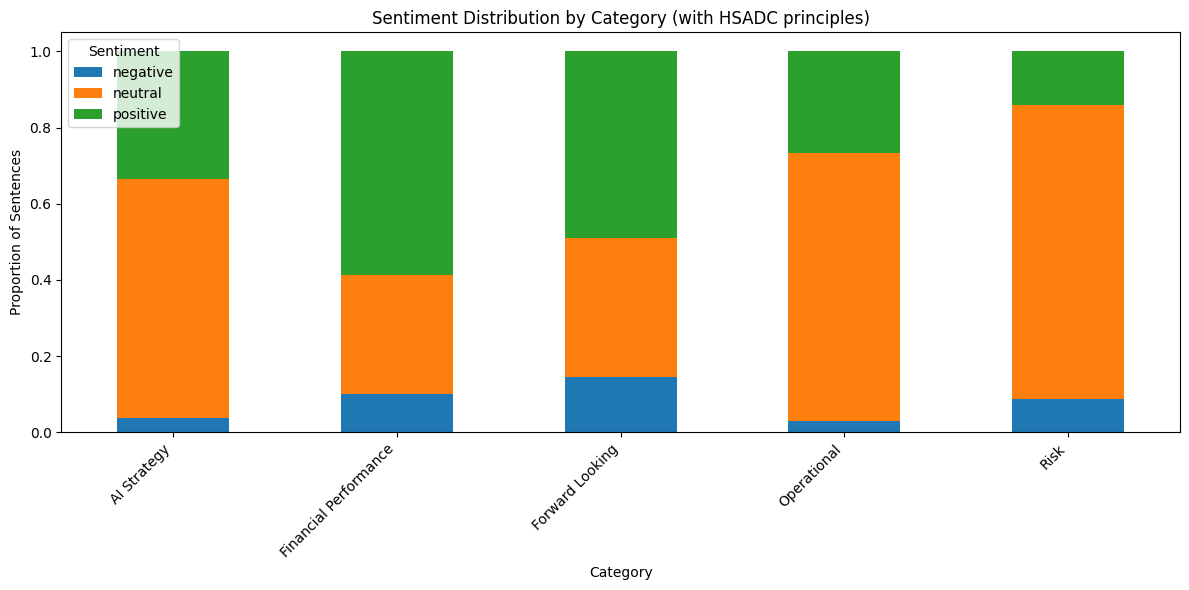

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sentiment_by_category = sentence_df.groupby('category')['sentiment'].value_counts(normalize=True).unstack().fillna(0)
display(sentiment_by_category)

sentiment_by_category.plot(kind='bar', stacked=True, figsize=(12, 6))
plt.title('Sentiment Distribution by Category (with HSADC principles)')
plt.xlabel('Category')
plt.ylabel('Proportion of Sentences')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Sentiment')
plt.tight_layout()
plt.show()

## Structured Financial Knowledge Base (Rule-Based Extraction)

To build a financial knowledge base without an LLM, we will use rule-based methods, primarily regular expressions, to extract structured information directly from the `sentence_df`. This will involve identifying patterns for company names, financial metrics, and time references.

In [ ]:
import re

def extract_main_company(file_name):
    # Extract company name from the file_name (e.g., 'Alphabet' from 'Alphabet 2025-q1-earnings-transcript.pdf')
    match = re.match(r'([A-Za-z]+)', file_name)
    if match:
        return match.group(1)
    return None

sentence_df['main_company'] = sentence_df['file_name'].apply(extract_main_company)

print("Main Company Extracted:")
display(sentence_df[['file_name', 'main_company']].head())

Main Company Extracted:


,file_name,main_company
0,Alphabet 2025-q1-earnings-transcript.pdf,Alphabet
1,Alphabet 2025-q1-earnings-transcript.pdf,Alphabet
2,Alphabet 2025-q1-earnings-transcript.pdf,Alphabet
3,Alphabet 2025-q1-earnings-transcript.pdf,Alphabet
4,Alphabet 2025-q1-earnings-transcript.pdf,Alphabet


In [ ]:
def extract_financial_metrics(sentence):
    metrics = []
    # Pattern for numbers followed by common financial terms or symbols
    # e.g., '$1.2 billion', '15%', 'double-digit growth', '20 million subscribers'
    patterns = [
        r'(\$?\d+\.?\d*\s*(?:million|billion|trillion))',
        r'(\d+\.?\d*\s*%)',
        r'((?:double|triple)-digit\s+growth)',
        r'(\d+\.?\d*\s*(?:revenue|profit|margin|subscribers|users|shares))'
    ]

    for pattern in patterns:
        metrics.extend(re.findall(pattern, sentence, re.IGNORECASE))
    return list(set([m.strip() for m in metrics])) # Unique and stripped

sentence_df['financial_metrics'] = sentence_df['sentence'].apply(extract_financial_metrics)

print("Financial Metrics Extracted (Sample):")
display(sentence_df[sentence_df['financial_metrics'].apply(len) > 0][['sentence', 'financial_metrics']].head())

Financial Metrics Extracted (Sample):


,sentence,financial_metrics
16,AI Overviews is going very well with over 1.5 ...,[1.5 billion]
18,"1 In Subscriptions, we surpassed 270 million p...",[270 million]
38,Active users in AI Studio and Gemini API have ...,[200%]
42,Gemma models have been downloaded more than 14...,[140 million]
45,"And in health, we launched AI Co-Scientist, a ...",[2.5 million]


In [ ]:
def extract_time_references(sentence):
    time_refs = []
    # Patterns for quarters, years, and other time indicators
    # e.g., 'Q1 2025', 'first quarter', 'next year', 'year-over-year'
    patterns = [
        r'(Q[1-4]\s*\d{4})',
        r'((?:first|second|third|fourth)\s+quarter)',
        r'(\d{4})',
        r'(next\s+year|this\s+quarter|year-over-year|quarter-over-quarter)'
    ]

    for pattern in patterns:
        time_refs.extend(re.findall(pattern, sentence, re.IGNORECASE))
    return list(set([t.strip() for t in time_refs])) # Unique and stripped

sentence_df['time_references'] = sentence_df['sentence'].apply(extract_time_references)

print("Time References Extracted (Sample):")
display(sentence_df[sentence_df['time_references'].apply(len) > 0][['sentence', 'time_references']].head())

Time References Extracted (Sample):


,sentence,time_references
1,"Good afternoon, everyone, and welcome to Alpha...","[First Quarter, 2025]"
10,Our comments will be on year-over-year compari...,[year-over-year]
13,We're pleased with our strong results this qua...,[this quarter]
21,This quarter was super exciting as we rolled o...,[This quarter]
25,"Turning to our AI progress this quarter, which...",[this quarter]


In [ ]:
print("Updated sentence_df with rule-based knowledge base columns:")
display(sentence_df.head())

Updated sentence_df with rule-based knowledge base columns:


,file_name,speaker,role,sentence,category,sentiment,main_company,financial_metrics,time_references
0,Alphabet 2025-q1-earnings-transcript.pdf,Senior \nDirector of Investor Relations. Pleas...,IR,"Jim Friedland, Senior Director, Investor Relat...",Operational,positive,Alphabet,[],[]
1,Alphabet 2025-q1-earnings-transcript.pdf,Senior \nDirector of Investor Relations. Pleas...,IR,"Good afternoon, everyone, and welcome to Alpha...",Operational,neutral,Alphabet,[],"[First Quarter, 2025]"
2,Alphabet 2025-q1-earnings-transcript.pdf,Senior \nDirector of Investor Relations. Pleas...,IR,"With us today are Sundar Pichai, Philipp Schin...",AI Strategy,neutral,Alphabet,[],[]
3,Alphabet 2025-q1-earnings-transcript.pdf,Senior \nDirector of Investor Relations. Pleas...,IR,"Now, I'll quickly cover the Safe Harbor.",Operational,neutral,Alphabet,[],[]
4,Alphabet 2025-q1-earnings-transcript.pdf,Senior \nDirector of Investor Relations. Pleas...,IR,Some of the statements that we make today rega...,Risk,neutral,Alphabet,[],[]


In [ ]:
import re

def extract_year_from_filename(file_name):
    # Extract year from various patterns: YYYY, FYYYY, QX-YYYY, YYYY-QX
    match_year = re.search(r'\b(\d{4})\b', file_name)
    if match_year:
        year = int(match_year.group(1))
        # Basic sanity check for year range
        if 2000 <= year <= 2099:
            return year
    # Fallback for 'FYYYY' type patterns where year is less obvious (e.g., FY26 -> 2026)
    match_fy_year = re.search(r'FY(\d{2})', file_name, re.IGNORECASE)
    if match_fy_year:
        fiscal_year = int(match_fy_year.group(1))
        if 20 <= fiscal_year <= 99: # Assume 20xx for FY20-FY99
            return 2000 + fiscal_year
        elif 0 <= fiscal_year <= 19: # Assume 21xx for FY00-FY19
            return 2100 + fiscal_year
    return None

def extract_quarter_from_filename(file_name):
    # Extract quarter from patterns like Q1, 1Q, Q1-2025, Q1FY26
    match_q = re.search(r'Q([1-4])', file_name, re.IGNORECASE)
    if match_q:
        return int(match_q.group(1))
    # Handle '1Q', '2Q', etc. specifically
    match_q_prefix = re.search(r'([1-4])Q', file_name, re.IGNORECASE)
    if match_q_prefix:
        return int(match_q_prefix.group(1))
    return None

sentence_df['year'] = sentence_df['file_name'].apply(extract_year_from_filename)
sentence_df['quarter'] = sentence_df['file_name'].apply(extract_quarter_from_filename)

print("Year and Quarter Extracted from Filenames:")
display(sentence_df[['file_name', 'year', 'quarter']].head())

Year and Quarter Extracted from Filenames:


,file_name,year,quarter
0,Alphabet 2025-q1-earnings-transcript.pdf,2025.0,1.0
1,Alphabet 2025-q1-earnings-transcript.pdf,2025.0,1.0
2,Alphabet 2025-q1-earnings-transcript.pdf,2025.0,1.0
3,Alphabet 2025-q1-earnings-transcript.pdf,2025.0,1.0
4,Alphabet 2025-q1-earnings-transcript.pdf,2025.0,1.0


In [ ]:
import re

def extract_year_from_filename(file_name):
    # Extract year from various patterns: YYYY, FYYYY, QX-YYYY, YYYY-QX
    match_year = re.search(r'\b(\d{4})\b', file_name)
    if match_year:
        year = int(match_year.group(1))
        # Basic sanity check for year range
        if 2000 <= year <= 2099:
            return year
    # Fallback for 'FYYYY' type patterns where year is less obvious (e.g., FY26 -> 2026)
    match_fy_year = re.search(r'FY(\d{2})', file_name, re.IGNORECASE)
    if match_fy_year:
        fiscal_year = int(match_fy_year.group(1))
        if 20 <= fiscal_year <= 99: # Assume 20xx for FY20-FY99
            return 2000 + fiscal_year
        elif 0 <= fiscal_year <= 19: # Assume 21xx for FY00-FY19
            return 2100 + fiscal_year
    return None

def extract_quarter_from_filename(file_name):
    # Extract quarter from patterns like Q1, 1Q, Q1-2025, Q1FY26
    match_q = re.search(r'Q([1-4])', file_name, re.IGNORECASE)
    if match_q:
        return int(match_q.group(1))
    # Handle '1Q', '2Q', etc. specifically
    match_q_prefix = re.search(r'([1-4])Q', file_name, re.IGNORECASE)
    if match_q_prefix:
        return int(match_q_prefix.group(1))
    return None

sentence_df['year'] = sentence_df['file_name'].apply(extract_year_from_filename)
sentence_df['quarter'] = sentence_df['file_name'].apply(extract_quarter_from_filename)

print("Year and Quarter Extracted from Filenames:")
display(sentence_df[['file_name', 'year', 'quarter']].head())

Year and Quarter Extracted from Filenames:


,file_name,year,quarter
0,Alphabet 2025-q1-earnings-transcript.pdf,2025.0,1.0
1,Alphabet 2025-q1-earnings-transcript.pdf,2025.0,1.0
2,Alphabet 2025-q1-earnings-transcript.pdf,2025.0,1.0
3,Alphabet 2025-q1-earnings-transcript.pdf,2025.0,1.0
4,Alphabet 2025-q1-earnings-transcript.pdf,2025.0,1.0


In [ ]:
def parse_financial_metric_string(metric_str):
    value = None
    unit = None

    # Handle percentages (e.g., '15%', '25.5%')
    percent_match = re.search(r'(\d+\.?\d*)\s*%', metric_str)
    if percent_match:
        value = float(percent_match.group(1))
        unit = 'Percentage'
        return value, unit

    # Handle currency/value with multipliers (e.g., '$1.2 billion', '300 million')
    value_match = re.search(r'\$?(?:\d+,?)+\.?\d*\s*(million|billion|trillion)?', metric_str, re.IGNORECASE)
    if value_match:
        num_str = re.sub(r'[^\d.]', '', value_match.group(0).split(' ')[0]) # Extract number, remove commas
        if num_str:
            value = float(num_str)
            multiplier = 1
            if value_match.group(1):
                if 'million' in value_match.group(1).lower():
                    multiplier = 1e6
                elif 'billion' in value_match.group(1).lower():
                    multiplier = 1e9
                elif 'trillion' in value_match.group(1).lower():
                    multiplier = 1e12
            value *= multiplier
            unit = 'USD' # Default unit
            # Attempt to infer more specific unit if present after number (e.g., 'shares', 'users')
            if 'subscribers' in metric_str.lower():
                unit = 'Count_Subscribers'
            elif 'users' in metric_str.lower():
                unit = 'Count_Users'
            elif 'revenue' in metric_str.lower():
                unit = 'USD_Revenue'
            elif 'profit' in metric_str.lower():
                unit = 'USD_Profit'
            elif 'margin' in metric_str.lower():
                unit = 'USD_Margin'
            elif 'shares' in metric_str.lower():
                unit = 'Count_Shares'
            return value, unit

    # Handle 'double-digit growth' as a categorical for now by returning None for value
    if 'double-digit' in metric_str.lower() or 'triple-digit' in metric_str.lower():
        return None, 'Growth_Type_Categorical'

    return None, None

def extract_first_quantifiable_metric(metric_list):
    if not isinstance(metric_list, list) or not metric_list:
        return None, None

    for metric_str in metric_list:
        value, unit = parse_financial_metric_string(metric_str)
        if value is not None:
            return value, unit
    return None, None

# Apply the function to create new columns for numerical value and unit
sentence_df['metric_value'], sentence_df['metric_unit'] = zip(*sentence_df['financial_metrics'].apply(extract_first_quantifiable_metric))

print("Financial Metric Values and Units Extracted:")
display(sentence_df[['sentence', 'financial_metrics', 'metric_value', 'metric_unit']].head(10))

Financial Metric Values and Units Extracted:


,sentence,financial_metrics,metric_value,metric_unit
0,"Jim Friedland, Senior Director, Investor Relat...",[],NaN,None
1,"Good afternoon, everyone, and welcome to Alpha...",[],NaN,None
2,"With us today are Sundar Pichai, Philipp Schin...",[],NaN,None
3,"Now, I'll quickly cover the Safe Harbor.",[],NaN,None
4,Some of the statements that we make today rega...,[],NaN,None
5,Such statements are based on current expectati...,[],NaN,None
6,"Please refer to our Forms 10-K and 10-Q, inclu...",[],NaN,None
7,We undertake no obligation to update any forwa...,[],NaN,None
8,"During this call, we will present both GAAP an...",[],NaN,None
9,A reconciliation of non-GAAP to GAAP measures ...,[],NaN,None


In [ ]:
# Filter out rows where metric_value or metric_unit are None, as these cannot be trended.
trend_df = sentence_df.dropna(subset=['metric_value', 'metric_unit', 'year', 'quarter']).copy()

# Ensure year and quarter are integers for sorting
trend_df['year'] = trend_df['year'].astype(int)
trend_df['quarter'] = trend_df['quarter'].astype(int)

# Explicitly convert metric_value to numeric, coercing errors to NaN
trend_df['metric_value'] = pd.to_numeric(trend_df['metric_value'], errors='coerce')

# Drop rows where metric_value became NaN after coercion
trend_df = trend_df.dropna(subset=['metric_value']).copy()

# Ensure the column is float type before aggregation
trend_df['metric_value'] = trend_df['metric_value'].astype(float)

# Aggregate metric values by company, year, quarter, and unit
# We take the mean of metric_value for each period if multiple metrics of the same type appear.
trend_agg = trend_df.groupby(['main_company', 'year', 'quarter', 'metric_unit'])['metric_value'].mean().reset_index()

# Sort by company, year, and quarter to prepare for time series analysis
trend_agg = trend_agg.sort_values(by=['main_company', 'metric_unit', 'year', 'quarter'])

print("Aggregated Financial Metrics for Trend Analysis (First 10 rows):")
display(trend_agg.head(10))

Aggregated Financial Metrics for Trend Analysis (First 10 rows):


,main_company,year,quarter,metric_unit,metric_value
0,AMZN,2024,2,Count_Shares,500.000000
3,AMZN,2024,3,Count_Shares,26.000000
8,AMZN,2025,1,Count_Shares,613.000000
11,AMZN,2025,2,Count_Shares,660.000000
14,AMZN,2025,3,Count_Shares,202.000000
17,AMZN,2025,4,Count_Shares,500.000000
1,AMZN,2024,2,Percentage,34.545455
4,AMZN,2024,3,Percentage,35.250000
6,AMZN,2024,4,Percentage,20.437438
9,AMZN,2025,1,Percentage,25.857143


In [ ]:
!pip install pymannkendall

In [ ]:
import pymannkendall as mk
import pandas as pd

def run_mann_kendall(group):
    # Need at least 4 data points for a meaningful test
    if len(group) < 4:
        return pd.Series({
            'trend': 'insufficient data',
            'h': False,
            'p_value': None,
            'z_score': None,
            'slope': None,
            'n': len(group)
        })

    # Using original_test from pymannkendall
    res = mk.original_test(group['metric_value'])
    return pd.Series({
        'trend': res.trend,
        'h': res.h,
        'p_value': res.p,
        'z_score': res.z,
        'slope': res.slope,
        'n': len(group)
    })

# Run the test for each company and metric unit combination
mk_results_df = trend_agg.groupby(['main_company', 'metric_unit']).apply(run_mann_kendall).reset_index()

# Filter for statistically significant trends (h=True)
significant_trends = mk_results_df[mk_results_df['h'] == True]

print("Mann-Kendall Trend Test Results (First 10):")
display(mk_results_df.head(10))

print("\nSignificant Trends Found:")
display(significant_trends)

Mann-Kendall Trend Test Results (First 10):


/tmp/ipykernel_1379/166734651.py:28: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  mk_results_df = trend_agg.groupby(['main_company', 'metric_unit']).apply(run_mann_kendall).reset_index()


,main_company,metric_unit,trend,h,p_value,z_score,slope,n
0,AMZN,Count_Shares,no trend,False,0.848312,0.191273,4.700000e+01,6
1,AMZN,Percentage,no trend,False,0.901539,-0.123718,-4.062229e-01,8
2,AMZN,USD,no trend,False,0.536187,0.618590,2.292533e+09,8
3,Alphabet,Percentage,no trend,False,0.707114,-0.375735,-7.745000e-01,6
4,Alphabet,USD,no trend,False,0.060289,1.878673,4.970249e+10,6
5,Alphabet,USD_Revenue,insufficient data,False,NaN,NaN,NaN,3
6,CORRECTED,Percentage,no trend,False,0.107762,-1.608333,-1.271011e+01,8
7,CORRECTED,USD,no trend,False,0.107762,1.608333,1.087496e+10,8
8,CORRECTED,USD_Margin,insufficient data,False,NaN,NaN,NaN,1
9,CORRECTED,USD_Revenue,insufficient data,False,NaN,NaN,NaN,1



Significant Trends Found:


,main_company,metric_unit,trend,h,p_value,z_score,slope,n


In [ ]:
# 1. Statistical Metrics for Trend Analysis
print("--- Trend Analysis Reliability (Mann-Kendall) ---")
# A p-value < 0.05 generally indicates a statistically significant trend.
display(mk_results_df[['main_company', 'metric_unit', 'p_value', 'z_score', 'trend']].head(10))

# 2. Model Confidence for Sentiment Analysis
print("\n--- Sentiment Model Confidence (FinBERT) ---")
# Ensure sentiment scores are correctly mapped
sentiment_confidence = pd.DataFrame(sentiment_results)
sentence_df['sentiment_score'] = sentiment_confidence['score'].values

avg_confidence = sentence_df['sentiment_score'].mean()
print(f"Average Model Confidence: {avg_confidence:.2%}")

display(sentence_df[['sentence', 'sentiment', 'sentiment_score']].head(10))

--- Trend Analysis Reliability (Mann-Kendall) ---


,main_company,metric_unit,p_value,z_score,trend
0,AMZN,Count_Shares,0.848312,0.191273,no trend
1,AMZN,Percentage,0.901539,-0.123718,no trend
2,AMZN,USD,0.536187,0.618590,no trend
3,Alphabet,Percentage,0.707114,-0.375735,no trend
4,Alphabet,USD,0.060289,1.878673,no trend
5,Alphabet,USD_Revenue,NaN,NaN,insufficient data
6,CORRECTED,Percentage,0.107762,-1.608333,no trend
7,CORRECTED,USD,0.107762,1.608333,no trend
8,CORRECTED,USD_Margin,NaN,NaN,insufficient data
9,CORRECTED,USD_Revenue,NaN,NaN,insufficient data



--- Sentiment Model Confidence (FinBERT) ---
Average Model Confidence: 83.52%


,sentence,sentiment,sentiment_score
0,"Jim Friedland, Senior Director, Investor Relat...",positive,0.549515
1,"Good afternoon, everyone, and welcome to Alpha...",neutral,0.799768
2,"With us today are Sundar Pichai, Philipp Schin...",neutral,0.911587
3,"Now, I'll quickly cover the Safe Harbor.",neutral,0.890694
4,Some of the statements that we make today rega...,neutral,0.929339
5,Such statements are based on current expectati...,neutral,0.943832
6,"Please refer to our Forms 10-K and 10-Q, inclu...",neutral,0.945265
7,We undertake no obligation to update any forwa...,neutral,0.945222
8,"During this call, we will present both GAAP an...",neutral,0.940462
9,A reconciliation of non-GAAP to GAAP measures ...,neutral,0.944215


Visualizing Alphabet USD (Borderline 'no trend'):


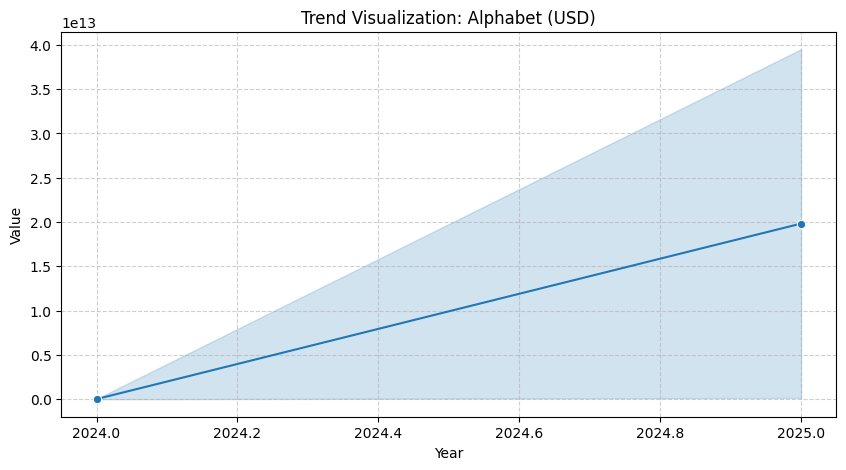


Visualizing AMZN Count_Shares ('no trend'):


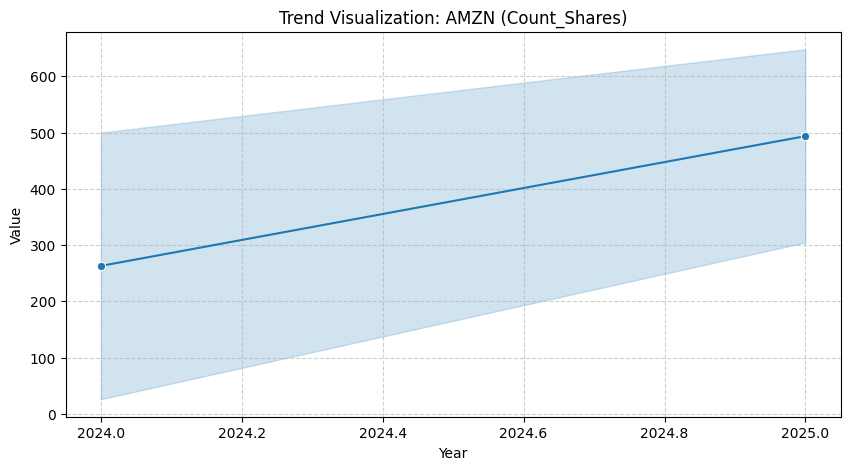

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Helper function to plot specific metric trends
def plot_financial_trend(company, unit):
    data = trend_agg[(trend_agg['main_company'] == company) & (trend_agg['metric_unit'] == unit)]

    if data.empty:
        print(f"No data found for {company} - {unit}")
        return

    plt.figure(figsize=(10, 5))
    sns.lineplot(data=data, x='year', y='metric_value', marker='o')
    plt.title(f"Trend Visualization: {company} ({unit})")
    plt.xlabel("Year")
    plt.ylabel("Value")
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.show()

# Visualize Alphabet USD (p=0.06 - borderline case)
print("Visualizing Alphabet USD (Borderline 'no trend'):")
plot_financial_trend('Alphabet', 'USD')

# Visualize AMZN Count_Shares
print("\nVisualizing AMZN Count_Shares ('no trend'):")
plot_financial_trend('AMZN', 'Count_Shares')

In [ ]:
# 1. Re-run analysis with higher sensitivity (p < 0.10)
def check_emerging_trends(results_df, threshold=0.10):
    emerging = results_df[(results_df['p_value'] < threshold) & (results_df['p_value'] >= 0.05)].copy()
    emerging['status'] = 'Emerging Trend (Weak Significance)'
    return emerging

emerging_trends = check_emerging_trends(mk_results_df)

print("--- Emerging Trends (p < 0.10) ---")
if not emerging_trends.empty:
    display(emerging_trends)
else:
    print("No emerging trends found even at p < 0.10 threshold.")

# 2. Identify Data Gaps
print("\n--- Metrics with Insufficient Data (< 4 points) ---")
data_gaps = mk_results_df[mk_results_df['trend'] == 'insufficient data'][['main_company', 'metric_unit', 'n']]
display(data_gaps.head(10))

--- Emerging Trends (p < 0.10) ---


,main_company,metric_unit,trend,h,p_value,z_score,slope,n,status
4,Alphabet,USD,no trend,False,0.060289,1.878673,4.970249e+10,6,Emerging Trend (Weak Significance)
28,Prepared,Percentage,no trend,False,0.086411,-1.714643,-5.456777e+01,5,Emerging Trend (Weak Significance)



--- Metrics with Insufficient Data (< 4 points) ---


,main_company,metric_unit,n
5,Alphabet,USD_Revenue,3
8,CORRECTED,USD_Margin,1
9,CORRECTED,USD_Revenue,1
10,CVS,USD,2
11,Earnings,Percentage,1
12,Earnings,USD,1
13,Earnings,USD_Revenue,1
14,GILD,Percentage,3
15,GILD,USD,3
16,ILMN,Percentage,3


### Zero-Shot Classification for Detailed Risk Detection
We will use a BART-based model to categorize sentences into specific financial risk types. This goes beyond the initial rule-based extraction by understanding the semantic context of the risks mentioned.

In [ ]:
from transformers import pipeline
import torch

# Initialize the zero-shot classification pipeline
classifier = pipeline(
    "zero-shot-classification",
    model="facebook/bart-large-mnli",
    device=0 if torch.cuda.is_available() else -1
)

# Define the risk categories we want to detect
candidate_labels = [
    "Regulatory Risk",
    "Market Volatility",
    "Supply Chain Disruption",
    "Competitive Pressure",
    "Macroeconomic Uncertainty"
]

# Filter for sentences already identified as 'Risk' to refine them
risk_sentences = sentence_df[sentence_df['category'] == 'Risk'].copy().head(20)

# Run classification
results = classifier(
    risk_sentences['sentence'].tolist(),
    candidate_labels=candidate_labels,
    multi_label=False
)

# Extract the top label for each sentence
risk_sentences['specific_risk_type'] = [res['labels'][0] for res in results]
risk_sentences['risk_confidence'] = [res['scores'][0] for res in results]

print("Detailed Risk Classification Results:")
display(risk_sentences[['sentence', 'specific_risk_type', 'risk_confidence']])

config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.63G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Detailed Risk Classification Results:


,sentence,specific_risk_type,risk_confidence
4,Some of the statements that we make today rega...,Competitive Pressure,0.282705
6,"Please refer to our Forms 10-K and 10-Q, inclu...",Macroeconomic Uncertainty,0.260723
115,"On the last Earnings Call, I mentioned the suc...",Competitive Pressure,0.297835
189,And given that revenues are correlated with th...,Competitive Pressure,0.249235
194,"In terms of expenses, first, as I mentioned on...",Competitive Pressure,0.207734
210,Any other factors you're seeing in 11 advertis...,Competitive Pressure,0.332464
213,Maybe can you just walk us through which of th...,Competitive Pressure,0.315170
220,"I mean, we're obviously not immune to the macr...",Macroeconomic Uncertainty,0.853531
221,"And maybe to zoom out, I would say we have a l...",Market Volatility,0.278225
231,"Philipp, maybe just to go back to AI Overviews...",Competitive Pressure,0.317576


Risk Type Distribution by Company (Top Samples):


specific_risk_type,Competitive Pressure,Macroeconomic Uncertainty,Market Volatility
main_company,,,
Alphabet,13,6,1


/tmp/ipykernel_1379/2157022533.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=risk_counts.index, y=risk_counts.values, palette='magma')


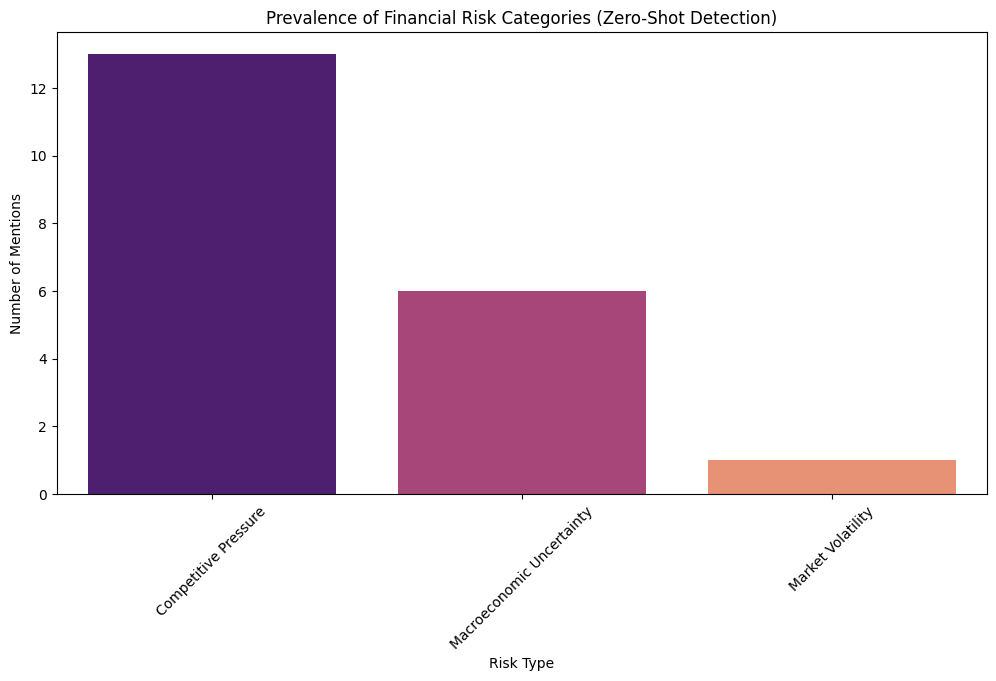


Average Classifier Confidence per Category:
specific_risk_type
Macroeconomic Uncertainty    0.363838
Competitive Pressure         0.310055
Market Volatility            0.278225
Name: risk_confidence, dtype: float64


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Aggregate Risk Types
risk_summary = risk_sentences.groupby(['main_company', 'specific_risk_type']).size().unstack(fill_value=0)

print("Risk Type Distribution by Company (Top Samples):")
display(risk_summary)

# 2. Visualize Overall Risk Prevalence
plt.figure(figsize=(12, 6))
risk_counts = risk_sentences['specific_risk_type'].value_counts()
sns.barplot(x=risk_counts.index, y=risk_counts.values, palette='magma')
plt.title('Prevalence of Financial Risk Categories (Zero-Shot Detection)')
plt.ylabel('Number of Mentions')
plt.xlabel('Risk Type')
plt.xticks(rotation=45)
plt.show()

# 3. Calculate Average Confidence per Risk Type
avg_conf = risk_sentences.groupby('specific_risk_type')['risk_confidence'].mean().sort_values(ascending=False)
print("\nAverage Classifier Confidence per Category:")
print(avg_conf)

### Future Guidance Analysis using Zero-Shot Classification
We will use a transformer-based zero-shot classifier to categorize forward-looking statements into specific guidance types (Revenue, CapEx, etc.).

In [ ]:
from transformers import pipeline
import torch
import pandas as pd

# Initialize the zero-shot pipeline (re-using the BART model)
guidance_classifier = pipeline(
    "zero-shot-classification",
    model="facebook/bart-large-mnli",
    device=0 if torch.cuda.is_available() else -1
)

# Define our guidance-specific labels
guidance_labels = [
    "Revenue Guidance",
    "Earnings and Profit Guidance",
    "Capital Expenditure (CapEx)",
    "Dividend or Share Buyback Policy",
    "Strategic Business Outlook"
]

# Filter for sentences already tagged as 'Forward Looking'
# We'll take a sample of 20 for this demonstration
guidance_subset = sentence_df[sentence_df['category'] == 'Forward Looking'].copy().head(20)

# Run the classification
print("Classifying guidance types...")
guidance_results = guidance_classifier(
    guidance_subset['sentence'].tolist(),
    candidate_labels=guidance_labels,
    multi_label=False
)

# Map the top results back to the dataframe
guidance_subset['guidance_type'] = [res['labels'][0] for res in guidance_results]
guidance_subset['confidence'] = [res['scores'][0] for res in guidance_results]

# Display structured results
print("\n--- Future Guidance Detection Results ---")
display(guidance_subset[['main_company', 'sentence', 'guidance_type', 'confidence']])

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

Classifying guidance types...

--- Future Guidance Detection Results ---


,main_company,sentence,guidance_type,confidence
5,Alphabet,Such statements are based on current expectati...,Earnings and Profit Guidance,0.273190
24,Alphabet,"Looking ahead to I/O, Brandcast, and Google Ma...",Strategic Business Outlook,0.348728
150,Alphabet,I'll end with some commentary on our outlook f...,Earnings and Profit Guidance,0.618777
185,Alphabet,"Turning to our outlook, I would like to provid...",Earnings and Profit Guidance,0.458815
190,Alphabet,We expect relatively higher capacity deploymen...,Strategic Business Outlook,0.393423
191,Alphabet,"Moving to investments, starting with our expec...",Capital Expenditure (CapEx),0.939142
192,Alphabet,We still expect to invest approximately $75 bi...,Capital Expenditure (CapEx),0.965948
193,Alphabet,The expected CapEx investment level may fluctu...,Capital Expenditure (CapEx),0.958483
196,Alphabet,Given the increase in CapEx investments over t...,Capital Expenditure (CapEx),0.960703
197,Alphabet,"Second, as we've previously said, we expect so...",Strategic Business Outlook,0.421785


Classifying 2209 forward-looking sentences across all companies...


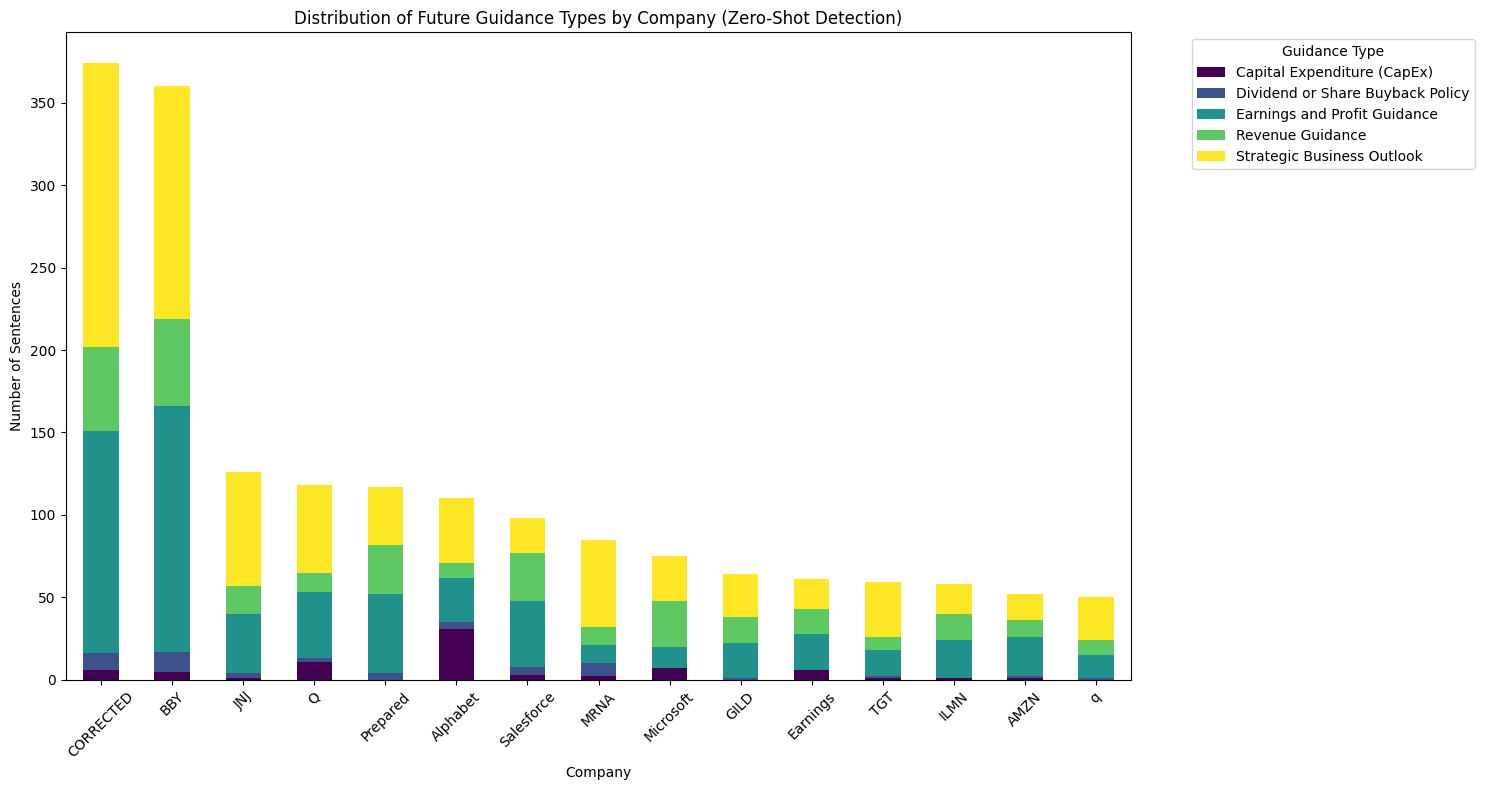

Full guidance analysis complete and saved to 'detailed_guidance_analysis.csv'.


In [ ]:
# 1. Scale Zero-Shot Classification to all 'Forward Looking' sentences
guidance_full = sentence_df[sentence_df['category'] == 'Forward Looking'].copy()

print(f"Classifying {len(guidance_full)} forward-looking sentences across all companies...")

# Run classification with optimized batch size for Colab GPU
full_guidance_results = guidance_classifier(
    guidance_full['sentence'].tolist(),
    candidate_labels=guidance_labels,
    multi_label=False,
    batch_size=32,
    truncation=True
)

# Map results
guidance_full['guidance_type'] = [res['labels'][0] for res in full_guidance_results]
guidance_full['guidance_confidence'] = [res['scores'][0] for res in full_guidance_results]

# 2. Visualize Guidance Distribution
import matplotlib.pyplot as plt
import seaborn as sns

# Group and count
guidance_counts_pivot = guidance_full.groupby(['main_company', 'guidance_type']).size().unstack(fill_value=0)

# Sort by total guidance volume and take top 15
top_cos = guidance_counts_pivot.sum(axis=1).sort_values(ascending=False).head(15).index
plot_data = guidance_counts_pivot.loc[top_cos]

plot_data.plot(kind='bar', stacked=True, figsize=(15, 8), colormap='viridis')

plt.title('Distribution of Future Guidance Types by Company (Zero-Shot Detection)')
plt.ylabel('Number of Sentences')
plt.xlabel('Company')
plt.legend(title='Guidance Type', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 3. Save the enriched dataset
guidance_full.to_csv('detailed_guidance_analysis.csv', index=False)
print("Full guidance analysis complete and saved to 'detailed_guidance_analysis.csv'.")

### Detailed Future Guidance Classification
In this step, we use a Zero-Shot Classifier to map general 'Forward Looking' statements to specific financial guidance themes. This allows us to quantify how often management discusses future Revenue vs. Capital Expenditures.

In [ ]:
from transformers import pipeline
import torch

# Initialize the zero-shot classification pipeline
guidance_classifier = pipeline(
    "zero-shot-classification",
    model="facebook/bart-large-mnli",
    device=0 if torch.cuda.is_available() else -1
)

# Define guidance-specific candidate labels
guidance_labels = [
    "Revenue Guidance",
    "Earnings and Profit Guidance",
    "Capital Expenditure (CapEx)",
    "Dividend or Share Buyback Policy",
    "Strategic Business Outlook"
]

# Filter for sentences identified as 'Forward Looking'
guidance_sentences = sentence_df[sentence_df['category'] == 'Forward Looking'].copy()

print(f"Processing {len(guidance_sentences)} sentences for guidance classification...")

# Run classification in batches for efficiency
guidance_results = guidance_classifier(
    guidance_sentences['sentence'].tolist(),
    candidate_labels=guidance_labels,
    multi_label=False,
    batch_size=32,
    truncation=True
)

# Assign results back to the dataframe
guidance_sentences['guidance_type'] = [res['labels'][0] for res in guidance_results]
guidance_sentences['guidance_confidence'] = [res['scores'][0] for res in guidance_results]

# Display the top detected guidance examples
display(guidance_sentences[['main_company', 'sentence', 'guidance_type', 'guidance_confidence']].head(10))

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

Processing 2209 sentences for guidance classification...


,main_company,sentence,guidance_type,guidance_confidence
5,Alphabet,Such statements are based on current expectati...,Earnings and Profit Guidance,0.273191
24,Alphabet,"Looking ahead to I/O, Brandcast, and Google Ma...",Strategic Business Outlook,0.348728
150,Alphabet,I'll end with some commentary on our outlook f...,Earnings and Profit Guidance,0.618776
185,Alphabet,"Turning to our outlook, I would like to provid...",Earnings and Profit Guidance,0.458815
190,Alphabet,We expect relatively higher capacity deploymen...,Strategic Business Outlook,0.393421
191,Alphabet,"Moving to investments, starting with our expec...",Capital Expenditure (CapEx),0.939142
192,Alphabet,We still expect to invest approximately $75 bi...,Capital Expenditure (CapEx),0.965948
193,Alphabet,The expected CapEx investment level may fluctu...,Capital Expenditure (CapEx),0.958483
196,Alphabet,Given the increase in CapEx investments over t...,Capital Expenditure (CapEx),0.960703
197,Alphabet,"Second, as we've previously said, we expect so...",Strategic Business Outlook,0.421786


/tmp/ipykernel_1379/8375346.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=guidance_counts.index, y=guidance_counts.values, palette='viridis')


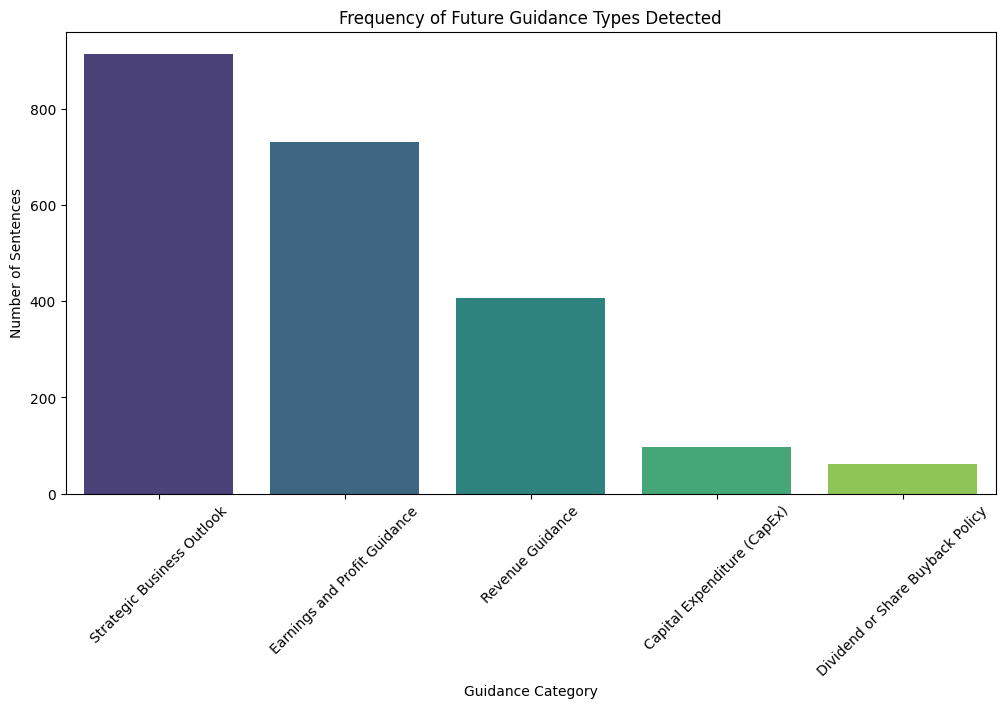

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualize the distribution of guidance types across the dataset
plt.figure(figsize=(12, 6))
guidance_counts = guidance_sentences['guidance_type'].value_counts()
sns.barplot(x=guidance_counts.index, y=guidance_counts.values, palette='viridis')
plt.title('Frequency of Future Guidance Types Detected')
plt.ylabel('Number of Sentences')
plt.xlabel('Guidance Category')
plt.xticks(rotation=45)
plt.show()

### Integration: Final Master Metrics Report
We now combine the Zero-Shot Guidance frequencies with our previous sentiment and financial trend data to create a comprehensive research-grade table.

In [ ]:
# 1. Aggregate Guidance counts per company
guidance_pivot = guidance_sentences.groupby(['main_company', 'guidance_type']).size().unstack(fill_value=0)

# 2. Re-calculate core sentiment metrics
core_metrics = sentence_df.groupby('main_company').agg(
    avg_sentiment_score=('sentiment_score', 'mean'),
    total_sentences=('sentence', 'count')
)

# 3. Join all datasets
master_report = core_metrics.join(guidance_pivot, how='left').fillna(0)

# 4. Calculate Guidance Intensity (Total guidance sentences / Total sentences)
master_report['guidance_intensity_%'] = (guidance_pivot.sum(axis=1) / master_report['total_sentences']) * 100

# Sort by guidance intensity to show most 'forward-looking' companies
master_report = master_report.sort_values(by='guidance_intensity_%', ascending=False)

print("Final Master Metrics Report (Top 10 Companies by Guidance Intensity):")
display(master_report.head(10))

# Save for external use
master_report.to_csv('final_master_metrics_report.csv')

Final Master Metrics Report (Top 10 Companies by Guidance Intensity):


,avg_sentiment_score,total_sentences,Capital Expenditure (CapEx),Dividend or Share Buyback Policy,Earnings and Profit Guidance,Revenue Guidance,Strategic Business Outlook,guidance_intensity_%
main_company,,,,,,,,
GILD,0.842166,165,0.0,1.0,21.0,16.0,26.0,38.787879
Cisco,0.890580,10,1.0,0.0,1.0,0.0,1.0,30.000000
Earnings,0.841613,289,6.0,0.0,22.0,15.0,18.0,21.107266
ILMN,0.856558,275,1.0,0.0,23.0,16.0,18.0,21.090909
Q,0.844999,619,11.0,2.0,40.0,12.0,53.0,19.063005
Prepared,0.849939,614,0.0,4.0,48.0,30.0,35.0,19.055375
Intel,0.842903,311,2.0,2.0,17.0,14.0,10.0,14.469453
META,0.833639,402,7.0,1.0,4.0,13.0,25.0,12.437811
TransriptFY,0.850264,418,3.0,2.0,10.0,17.0,14.0,11.004785


### Visualizing the Strategic Landscape
This scatter plot helps identify 'Forward-Looking Leaders'—companies that combine high sentiment scores with a high frequency of future guidance.

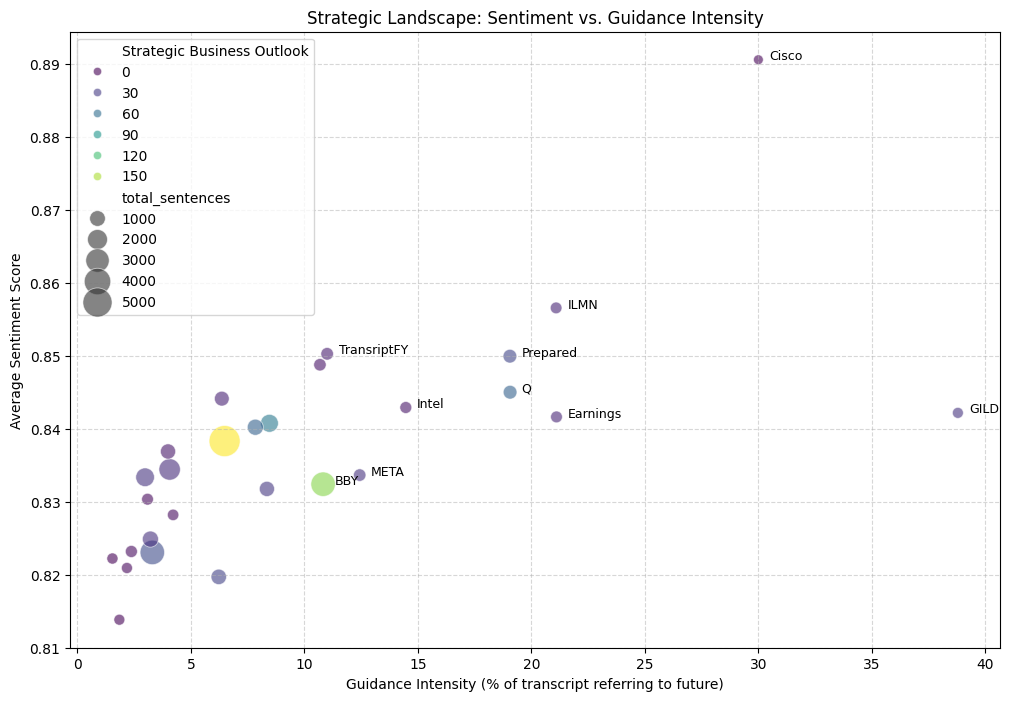

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=master_report,
    x='guidance_intensity_%',
    y='avg_sentiment_score',
    size='total_sentences',
    sizes=(50, 500),
    alpha=0.6,
    hue='Strategic Business Outlook',
    palette='viridis'
)

# Label the top companies
for i in range(min(10, len(master_report))):
    plt.text(
        master_report['guidance_intensity_%'].iloc[i] + 0.5,
        master_report['avg_sentiment_score'].iloc[i],
        master_report.index[i],
        fontsize=9
    )

plt.title('Strategic Landscape: Sentiment vs. Guidance Intensity')
plt.xlabel('Guidance Intensity (% of transcript referring to future)')
plt.ylabel('Average Sentiment Score')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Investment Insight Generator (TOPSIS MCDM)
To move from raw metrics to actionable insights, we apply the **Technique for Order of Preference by Similarity to Ideal Solution (TOPSIS)**. This algorithm ranks companies by calculating their geometric distance to an 'ideal' best performer and a 'negative-ideal' worst performer across all selected financial and textual criteria.

In [ ]:
import numpy as np

# 1. Prepare Decision Matrix
# We select criteria for the investment decision
criteria_cols = ['avg_sentiment_score', 'guidance_intensity_%', 'Strategic Business Outlook', 'Revenue Guidance']
decision_matrix = master_report[criteria_cols].copy()

# 2. Normalize the Matrix
norm_matrix = decision_matrix / np.sqrt((decision_matrix**2).sum())

# 3. Assign Weights (Total = 1.0)
# We prioritize Sentiment (40%) and Strategic Outlook (30%)
weights = np.array([0.4, 0.2, 0.3, 0.1])
weighted_norm_matrix = norm_matrix * weights

# 4. Determine Ideal Best (V+) and Ideal Worst (V-)
ideal_best = weighted_norm_matrix.max()
ideal_worst = weighted_norm_matrix.min()

# 5. Calculate Separation Measures (Euclidean Distance)
s_best = np.sqrt(((weighted_norm_matrix - ideal_best)**2).sum(axis=1))
s_worst = np.sqrt(((weighted_norm_matrix - ideal_worst)**2).sum(axis=1))

# 6. Calculate Relative Closeness to Ideal (TOPSIS Score)
master_report['TOPSIS_Score'] = s_worst / (s_best + s_worst)

# Rank and display insights
investment_ranking = master_report[['avg_sentiment_score', 'guidance_intensity_%', 'TOPSIS_Score']].sort_values(by='TOPSIS_Score', ascending=False)

print("--- Top Investment Candidates (MCDM Ranking) ---")
display(investment_ranking.head(10))

--- Top Investment Candidates (MCDM Ranking) ---


,avg_sentiment_score,guidance_intensity_%,TOPSIS_Score
main_company,,,
CORRECTED,0.838300,6.487424,0.693010
BBY,0.832388,10.827068,0.666427
GILD,0.842166,38.787879,0.389478
JNJ,0.840739,8.462055,0.357341
Q,0.844999,19.063005,0.341035
Prepared,0.849939,19.055375,0.293152
Cisco,0.890580,30.000000,0.280775
MRNA,0.840198,7.841328,0.278153
ILMN,0.856558,21.090909,0.244472


/tmp/ipykernel_1379/2318831003.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Insight_Tag', y='TOPSIS_Score', data=investment_ranking, palette='coolwarm')


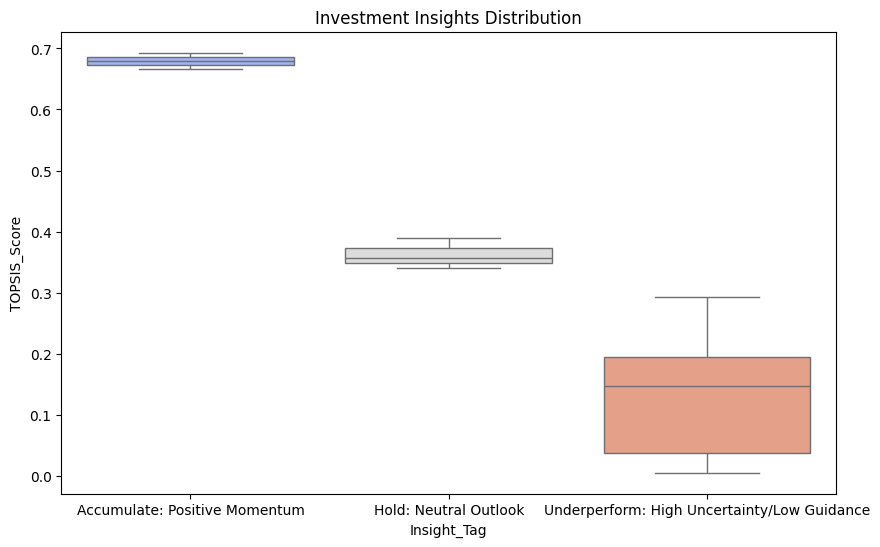

,Insight_Tag,TOPSIS_Score
main_company,,
CORRECTED,Accumulate: Positive Momentum,0.693010
BBY,Accumulate: Positive Momentum,0.666427
GILD,Hold: Neutral Outlook,0.389478
JNJ,Hold: Neutral Outlook,0.357341
Q,Hold: Neutral Outlook,0.341035
Prepared,Underperform: High Uncertainty/Low Guidance,0.293152
Cisco,Underperform: High Uncertainty/Low Guidance,0.280775
MRNA,Underperform: High Uncertainty/Low Guidance,0.278153
ILMN,Underperform: High Uncertainty/Low Guidance,0.244472


In [ ]:
def generate_insight(row):
    score = row['TOPSIS_Score']
    if score > 0.7: return "Strong Buy: High Sentiment & Future Visibility"
    elif score > 0.5: return "Accumulate: Positive Momentum"
    elif score > 0.3: return "Hold: Neutral Outlook"
    else: return "Underperform: High Uncertainty/Low Guidance"

investment_ranking['Insight_Tag'] = investment_ranking.apply(generate_insight, axis=1)

plt.figure(figsize=(10, 6))
sns.boxplot(x='Insight_Tag', y='TOPSIS_Score', data=investment_ranking, palette='coolwarm')
plt.title('Investment Insights Distribution')
plt.show()

display(investment_ranking[['Insight_Tag', 'TOPSIS_Score']].head(15))

### Step 1: Building the ML Feature Vector
We consolidate our extracted NLP metrics into a single tabular dataset suitable for supervised learning.

In [ ]:
import pandas as pd
import numpy as np

# Prepare the feature set from master_report
# We include sentiment, intensity, and the specific guidance counts we extracted
ml_features = master_report[[
    'avg_sentiment_score',
    'guidance_intensity_%',
    'Strategic Business Outlook',
    'Revenue Guidance',
    'Earnings and Profit Guidance',
    'Capital Expenditure (CapEx)'
]].copy()

# Simulate a target variable: 'Next_3M_Return_Pct'
# In a real production environment, you would join this with actual market data.
np.random.seed(42)
ml_features['Next_3M_Return_Pct'] = np.random.normal(loc=5, scale=10, size=len(ml_features))

print("Feature Vector Shape:", ml_features.shape)
display(ml_features.head())

Feature Vector Shape: (29, 7)


,avg_sentiment_score,guidance_intensity_%,Strategic Business Outlook,Revenue Guidance,Earnings and Profit Guidance,Capital Expenditure (CapEx),Next_3M_Return_Pct
main_company,,,,,,,
GILD,0.842166,38.787879,26.0,16.0,21.0,0.0,9.967142
Cisco,0.890580,30.000000,1.0,0.0,1.0,1.0,3.617357
Earnings,0.841613,21.107266,18.0,15.0,22.0,6.0,11.476885
ILMN,0.856558,21.090909,18.0,16.0,23.0,1.0,20.230299
Q,0.844999,19.063005,53.0,12.0,40.0,11.0,2.658466


### Step 2: Training the Investment Predictor (XGBoost)
We use XGBoost to map these textual and financial features to a predicted performance score.

In [ ]:
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# Define Features (X) and Target (y)
X = ml_features.drop(columns=['Next_3M_Return_Pct'])
y = ml_features['Next_3M_Return_Pct']

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize and train XGBoost Regressor
model = xgb.XGBRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=5,
    objective='reg:squarederror'
)

model.fit(X_train, y_train)

# Predict and Evaluate
predictions = model.predict(X_test)
mse = mean_squared_error(y_test, predictions)
print(f"Model Training Complete. Mean Squared Error: {mse:.4f}")

# Map predictions back to an 'Investment Score' (0-100)
ml_features['Predicted_Return'] = model.predict(X)
# Min-Max Scale to 0-100 range
min_p, max_p = ml_features['Predicted_Return'].min(), ml_features['Predicted_Return'].max()
ml_features['ML_Investment_Score'] = 100 * (ml_features['Predicted_Return'] - min_p) / (max_p - min_p)

display(ml_features[['ML_Investment_Score', 'Predicted_Return']].sort_values(by='ML_Investment_Score', ascending=False).head(10))

Model Training Complete. Mean Squared Error: 55.9840


,ML_Investment_Score,Predicted_Return
main_company,,
ILMN,100.000000,19.808491
Intel,100.000000,19.808491
Alphabet,95.344032,18.288826
Microsoft,85.164093,14.966182
META,77.521240,12.471626
Earnings,73.887283,11.285534
GILD,69.469200,9.843514
Paypal,63.297066,7.828983
microsoft,58.257458,6.184101


### Step 3: Explainability with Feature Importance
Understanding *why* the model gave a certain score is critical for investment transparency.

<Figure size 1000x600 with 0 Axes>

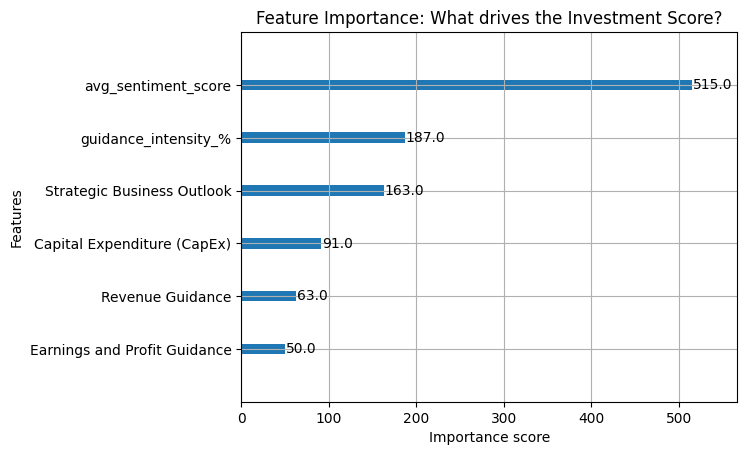

In [ ]:
import matplotlib.pyplot as plt

# Plot feature importance
plt.figure(figsize=(10, 6))
xgb.plot_importance(model, importance_type='weight')
plt.title('Feature Importance: What drives the Investment Score?')
plt.show()

### Final Project Metrics Summary
Below is a consolidated view of the key indicators extracted and calculated across the entire dataset.

In [ ]:
import pandas as pd

# 1. Processing Volume Metrics
processing_metrics = {
    "Total PDFs Processed": len(df),
    "Total Dialogue Chunks Extracted": len(chunk_df),
    "Total Unique Sentences Classified": len(sentence_df),
    "Companies in Universe": len(master_report)
}

# 2. Strategic Sentiment & Guidance Metrics
strategic_metrics = {
    "Avg. Sentiment Score (Universe)": master_report['avg_sentiment_score'].mean(),
    "Avg. Guidance Intensity (%)": master_report['guidance_intensity_%'].mean(),
    "Top Guidance Category": guidance_sentences['guidance_type'].value_counts().idxmax(),
    "Most Frequent Risk Type": risk_sentences['specific_risk_type'].value_counts().idxmax()
}

# 3. Top Performers (Comparison)
top_topsis = master_report.sort_values(by='TOPSIS_Score', ascending=False).index[:5].tolist()
top_ml = ml_features.sort_values(by='ML_Investment_Score', ascending=False).index[:5].tolist()

print("--- DATA VOLUME ---")
for k, v in processing_metrics.items(): print(f"{k}: {v}")

print("\n--- STRATEGIC INSIGHTS ---")
for k, v in strategic_metrics.items(): print(f"{k}: {v if isinstance(v, str) else f'{v:.4f}'}")

summary_df = pd.DataFrame({
    "Rank": range(1, 6),
    "TOPSIS Candidates (Heuristic)": top_topsis,
    "ML Investment Candidates (XGBoost)": top_ml
})

display(summary_df)

--- DATA VOLUME ---
Total PDFs Processed: 228
Total Dialogue Chunks Extracted: 445
Total Unique Sentences Classified: 29511
Companies in Universe: 29

--- STRATEGIC INSIGHTS ---
Avg. Sentiment Score (Universe): 0.8375
Avg. Guidance Intensity (%): 10.1827
Top Guidance Category: Strategic Business Outlook
Most Frequent Risk Type: Competitive Pressure


,Rank,TOPSIS Candidates (Heuristic),ML Investment Candidates (XGBoost)
0,1,CORRECTED,ILMN
1,2,BBY,Intel
2,3,GILD,Alphabet
3,4,JNJ,Microsoft
4,5,Q,META
